## Cellpose-SAM: superhuman generalization for cellular segmentation

Marius Pachitariu, Michael Rariden, Carsen Stringer

[paper](https://www.biorxiv.org/content/10.1101/2025.04.28.651001v1) | [code](https://github.com/MouseLand/cellpose)

This notebook shows how to process your own 2D or 3D images, saved on Google Drive.

This notebook is adapted from the notebook by Pradeep Rajasekhar, inspired by the [ZeroCostDL4Mic notebook series](https://github.com/HenriquesLab/ZeroCostDL4Mic/wiki).

### Make sure you have GPU access enabled by going to Runtime -> Change Runtime Type -> Hardware accelerator and selecting GPU

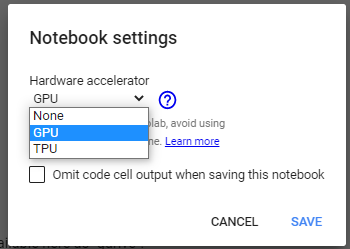

### Install Cellpose-SAM


In [ ]:
!uv pip install git+https://www.github.com/mouseland/cellpose.git

Check GPU and instantiate model - will download weights.

In [2]:
import numpy as np
from cellpose import models, core, io, plot
from pathlib import Path
from tqdm import trange
import matplotlib.pyplot as plt

io.logger_setup() # run this to get printing of progress

#Check if colab notebook instance has GPU access
if core.use_gpu()==False:
  raise ImportError("No GPU access, change your runtime")

model = models.CellposeModel(gpu=True)

[GUI INFO] : WRITING LOG OUTPUT TO C:\Users\20223228\.cellpose\run.log

cellpose version: 	4.2.1.1 
platform:       	win32 
python version: 	3.12.14 
torch version:  	2.14.0+cu126
2026-10-13 18:24:48,561 [io INFO] WRITING LOG OUTPUT TO C:\Users\20223228\.cellpose\run.log
2026-10-13 18:24:48,563 [io INFO] 
cellpose version: 	4.2.1.1 
platform:       	win32 
python version: 	3.12.14 
torch version:  	2.14.0+cu126
2026-10-13 18:24:48,829 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-13 18:24:48,829 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-13 18:24:48,829 [core INFO] >>>> using GPU (CUDA)
2026-10-13 18:24:51,408 [models INFO] >>>> loading model C:\Users\20223228\.cellpose\models\cpsam_v2


Input directory with your images (if you have them, otherwise use sample images):

In [4]:
# *** change to train folder path ***
train_dir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\test\\Austen_test"
if not Path(train_dir).exists():
  raise FileNotFoundError("directory does not exist")

test_dir = None # optionally you can specify a directory with test files

# *** change to your mask extension ***
masks_ext = "_seg.npy"
# ^ assumes images from Cellpose GUI, if labels are tiffs, then "_masks.tif"

# list all files
files = [f for f in Path(train_dir).glob("*") if "_masks" not in f.name and "_flows" not in f.name and "_seg" not in f.name]

if(len(files)==0):
  raise FileNotFoundError("no files found, did you specify the correct folder and extension?")
else:
  print(f"{len(files)} files in training folder:")

for f in files:
  print(f.name)

2 files in training folder:
m0_plate2_PointA5_R01_im_Composite_PC_DAPI_Seq0182_Dapi_8bit.tif
m1_plate2_PointA1_R01_im_Composite_PC_DAPI_Seq0038_Dapi_8bit.tif


## Train new model

In [ ]:
from cellpose import train

model_name = "input_model_name"

# default training params
n_epochs = 100 #default is 100
learning_rate = 1e-5
weight_decay = 0.1
batch_size = 1

# get files
output = io.load_train_test_data(train_dir, test_dir, mask_filter=masks_ext)
train_data, train_labels, _, test_data, test_labels, _ = output
# (not passing test data into function to speed up training)

new_model_path, train_losses, test_losses = train.train_seg(model.net,
                                                            train_data=train_data,
                                                            train_labels=train_labels,
                                                            batch_size=batch_size,
                                                            n_epochs=n_epochs,
                                                            learning_rate=learning_rate,
                                                            weight_decay=weight_decay,
                                                            nimg_per_epoch=max(2, len(train_data)), # can change this
                                                            model_name=model_name)


2026-10-07 14:38:55,870 [io INFO] not all flows are present, running flow generation for all images
2026-10-07 14:38:56,132 [io INFO] 1 / 1 images in C:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\train\try_train folder have labels
2026-10-07 14:38:56,140 [dynamics INFO] computing flows for labels
2026-10-07 14:39:09,737 [train INFO] >>> computing diameters


100%|██████████| 1/1 [00:00<00:00, 26.00it/s]

2026-10-07 14:39:09,791 [train INFO] >>> normalizing {'lowhigh': None, 'percentile': None, 'normalize': True, 'norm3D': True, 'sharpen_radius': 0, 'smooth_radius': 0, 'tile_norm_blocksize': 0, 'tile_norm_smooth3D': 1, 'invert': False}
2026-10-07 14:39:09,911 [train INFO] >>> n_epochs=30, n_train=1, n_test=None, bsize=256, batch_size=1, nimg_per_epoch=2
2026-10-07 14:39:09,921 [train INFO] >>> AdamW, learning_rate=0.00001, weight_decay=0.10000
2026-10-07 14:39:09,921 [train INFO] >>> saving model to c:\Users\20223228\OneDrive - TU Eindhoven\Documents\GitHub\BEP2026\models\try_model_pc_only


2026-10-07 14:39:37,569 [train INFO] 0, train_loss=5.7180, test_loss=0.0000, LR=0.000000, time 27.64s
2026-10-07 14:42:38,051 [train INFO] 5, train_loss=4.6640, test_loss=0.0000, LR=0.000006, time 208.13s
2026-10-07 14:45:55,171 [train INFO] 10, train_loss=3.9526, test_loss=0.0000, LR=0.000010, time 405.25s
2026-10-07 14:52:20,911 [train INFO] 20, train_loss=3.9354, test_loss=0.0000, LR=0.000010, time 790.99s
2026-10-07 14:57:38,690 [train INFO] saving network parameters to c:\Users\20223228\OneDrive - TU Eindhoven\Documents\GitHub\BEP2026\models\try_model_pc_only


## Evaluate on test data (optional)

If you have test data, check performance

In [ ]:
#code for testing on images together in test dataset folder

from cellpose import metrics

model = models.CellposeModel(pretrained_model='C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\models\\austen', gpu=True)
train_dir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\train\\Austen_train"
test_dir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\test\\Austen_test"
masks_ext = "_seg.npy"

output = io.load_train_test_data(train_dir, test_dir, mask_filter=masks_ext)
train_data, train_labels, _, test_data, test_labels, _ = output
test_files = sorted(Path(test_dir).glob("*.tif"))

# run model on test images
masks = model.eval(test_data, batch_size=1)[0] #default batch_size was 16, I changed to 1 to avoid memory issues. Other parameters can be changed as well

# check performance using ground truth labels
ap = metrics.average_precision(test_labels,masks,threshold=[0.5, 0.75, 0.9])[0]

aji = metrics.aggregated_jaccard_index(test_labels, masks)

precision, recall, fscore = metrics.boundary_scores(test_labels, masks, scales=[1.0])

print(f"AP50 = {ap[:,0].mean():.3f} ± {ap[:,0].std():.3f}")
print(f"AP75 = {ap[:,1].mean():.3f} ± {ap[:,1].std():.3f}")
print(f"AP90 = {ap[:,2].mean():.3f} ± {ap[:,2].std():.3f}")

print(f"AJI = {aji.mean():.3f} ± {aji.std():.3f}")

print(f"Boundary F-score = {fscore.mean():.3f} ± {fscore.std():.3f}")

2026-10-07 16:26:42,147 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-07 16:26:42,149 [core INFO] >>>> using GPU (CUDA)
2026-10-07 16:26:44,779 [models INFO] >>>> loading model C:\Users\20223228\OneDrive - TU Eindhoven\Documents\GitHub\BEP2026\models\try_model_pc_only
2026-10-07 16:26:46,289 [io INFO] not all flows are present, running flow generation for all images
2026-10-07 16:26:46,503 [io INFO] 1 / 1 images in C:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\train\try_train folder have labels
2026-10-07 16:26:46,508 [io INFO] not all flows are present, running flow generation for all images
2026-10-07 16:26:46,703 [io INFO] 1 / 1 images in C:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\test\test_try folder have labels
AP50 = 0.357 ± 0.000
AP75 = 0.154 ± 0.000
AP90 = 0.001 ± 0.000
AJI = 0.479 ± 0.000
Boundary F-score = 0.994 ± 0.000


In [5]:
#code for testing on images one by one in test dataset folder

from cellpose import metrics
from pathlib import Path

model = models.CellposeModel(pretrained_model='C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\models\\austen', gpu=True)
train_dir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\train\\Austen_train"
test_dir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\test\\Austen_test"
masks_ext = "_seg.npy"

output = io.load_train_test_data(train_dir, test_dir, mask_filter=masks_ext)
train_data, train_labels, _, test_data, test_labels, _ = output
test_files = sorted(Path(test_dir).glob("*.tif"))

# run model on test images
masks = model.eval(test_data, batch_size=1, flow_threshold=0.8)[0] #default batch_size was 16, I changed to 1 to avoid memory issues. Other parameters can be changed as well

# check performance using ground truth labels
for i in range(len(test_data)):
    ap = metrics.average_precision(
        [test_labels[i]],
        [masks[i]],
        threshold=[0.5, 0.75, 0.9]
    )[0]

    aji = metrics.aggregated_jaccard_index(
        [test_labels[i]],
        [masks[i]]
    )

    _, _, fscore = metrics.boundary_scores(
        [test_labels[i]],
        [masks[i]],
        scales=[1.0]
    )

    print(f"Image {test_files[i].name}:")

    print(f"AP50 = {ap[0,0]:.3f}")
    print(f"AP75 = {ap[0,1]:.3f}")
    print(f"AP90 = {ap[0,2]:.3f}")

    print(f"AJI = {float(aji[0]):.3f}")

    print(f"Boundary F-score = {fscore[0,0]:.3f}")

print("Done!")

2026-10-13 18:25:37,479 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-13 18:25:37,481 [core INFO] >>>> using GPU (CUDA)
2026-10-13 18:25:39,990 [models INFO] >>>> loading model C:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\models\austen
2026-10-13 18:25:41,433 [io INFO] not all flows are present, running flow generation for all images
2026-10-13 18:25:42,097 [io INFO] 2 / 2 images in C:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\train\Austen_train folder have labels
2026-10-13 18:25:42,100 [io INFO] not all flows are present, running flow generation for all images
2026-10-13 18:25:42,435 [io INFO] 2 / 2 images in C:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\test\Austen_test folder have labels
2026-10-13 18:25:42,435 [utils INFO] 0%|          | 0/2 [00:00<?, ?it/s]


c:\Users\20223228\.conda\envs\cellposesam\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


2026-10-13 18:29:34,224 [utils INFO] 100%|##########| 2/2 [03:51<00:00, 115.89s/it]
Image m0_plate2_PointA5_R01_im_Composite_PC_DAPI_Seq0182_Dapi_8bit.tif:
AP50 = 0.392
AP75 = 0.069
AP90 = 0.000
AJI = 0.560
Boundary F-score = 0.996
Image m1_plate2_PointA1_R01_im_Composite_PC_DAPI_Seq0038_Dapi_8bit.tif:
AP50 = 0.463
AP75 = 0.177
AP90 = 0.011
AJI = 0.652
Boundary F-score = 0.996
Done!


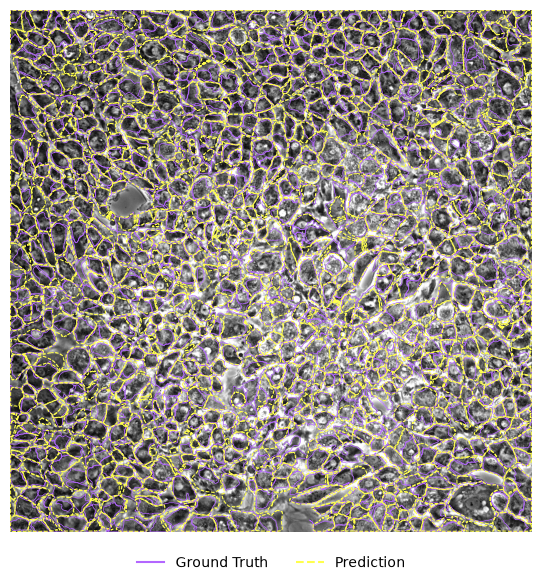

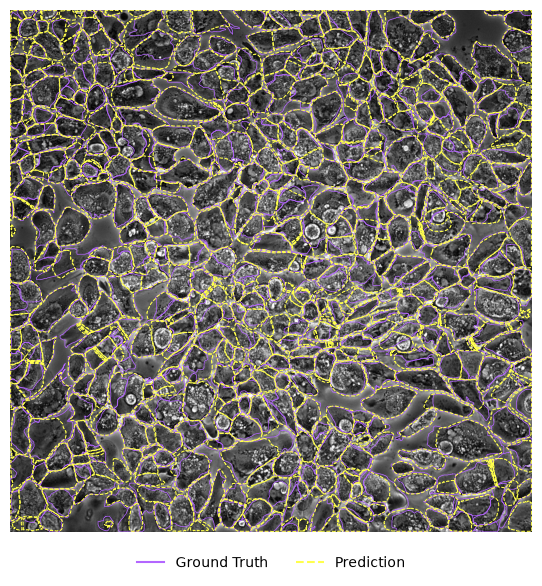

In [9]:
from cellpose import transforms, plot, utils
from matplotlib.lines import Line2D

imgs = test_data
masks_true = test_labels
masks_pred = masks

ly = 400
for iex in range(len(imgs)):
    fig, ax = plt.subplots(figsize=(6,6))
    img = imgs[iex].squeeze().copy()
    if img.ndim==2:
        img = np.stack((img, np.zeros_like(img)), axis=0)
    else:
        img = img.transpose(2,0,1)
        
    if img[1].sum()==0:
        img = img[0]
        ax.imshow(img, cmap="gray")
    else:
        # make RGB from 2 channel image
        img = np.concatenate((np.zeros_like(img)[:1], img), axis=0).transpose(1,2,0)
        ax.imshow(img)

    # GROUND-TRUTH = PURPLE
    # PREDICTED = YELLOW
    outlines_gt = utils.outlines_list(masks_true[iex])
    outlines_pred = utils.outlines_list(masks_pred[iex])
    for o in outlines_gt:
        plt.plot(o[:,0], o[:,1], color=[0.7,0.4,1], lw=0.5)
    for o in outlines_pred:
        plt.plot(o[:,0], o[:,1], color=[1,1,0.3], lw=0.75, ls="--")
    plt.axis('off')

    legend_elements = [Line2D([0], [0], color=[0.7,0.4,1], lw=1.5, label='Ground Truth'),
            Line2D([0], [0], color=[1,1,0.3], lw=1.5, ls='--', label='Prediction')]

    fig.legend(handles=legend_elements,
           loc='lower center',
           ncol=2,
           frameon=False,
           bbox_to_anchor=(0.5, 0.02))

    plt.tight_layout(rect=[0, 0.08, 1, 1])

    fig.savefig(
        f"overlay_{iex+1}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

plot masks

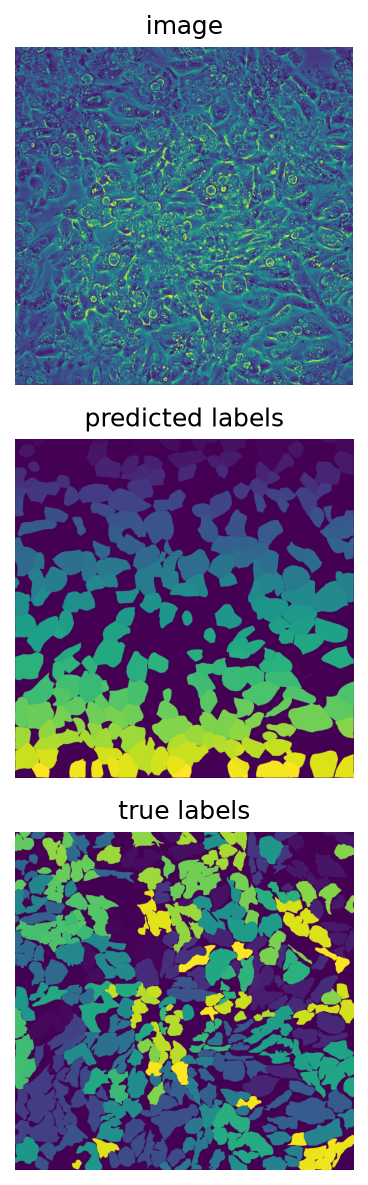

In [17]:
from cellpose import plot

plt.figure(figsize=(12,8), dpi=150)

for k,im in enumerate(test_data):
    img = im.copy()
    plt.subplot(3,len(test_data), k+1)
    img = np.vstack((img, np.zeros_like(img)[:1]))
    #img = img.transpose(1,2,0)
    plt.imshow(img)
    plt.axis('off')
    if k==0:
        plt.title('image')

    plt.subplot(3,len(test_data), len(test_data) + k+1)
    plt.imshow(masks[k])
    plt.axis('off')
    if k==0:
        plt.title('predicted labels')

    plt.subplot(3,len(test_data), 2*len(test_data) + k+1)
    plt.imshow(test_labels[k])
    plt.axis('off')
    if k==0:
        plt.title('true labels')
plt.tight_layout()